In [1]:
import numpy as np 
import pandas as pd
from sklearn.model_selection import train_test_split    
from lightgbm import LGBMClassifier

In [4]:
np.random.seed(42)
n_samples = 10000

# 1. Feature Engineering
tenure_months = np.random.exponential(scale=24, size=n_samples).clip(1, 120)
monthly_bill = np.random.normal(loc=120, scale=30, size=n_samples).clip(30, 300)
past_outages = np.random.poisson(lam=1.5, size=n_samples)

# 2. Random Treatment Assignment (50/50 A/B Test Promo Offer)
treatment = np.random.binomial(n=1, p=0.5, size=n_samples)

# 3. Simulate True Causal Uplift (Persuadables vs Sleeping Dogs)
# Persuadables: High monthly bill & high past outages respond strongly to promo
true_uplift = 0.05 + 0.001 * monthly_bill + 0.08 * past_outages - 0.002 * tenure_months

# Baseline retention probability (without treatment)
baseline_retention = 1 / (1 + np.exp(-(-1.5 + 0.03 * tenure_months - 0.01 * monthly_bill - 0.5 * past_outages)))

# Treatment retention probability
treated_retention = baseline_retention + true_uplift
treated_retention = np.clip(treated_retention, 0, 1)

# Observed Outcome Y (1 = Retained, 0 = Churned)
y_prob = np.where(treatment == 1, treated_retention, baseline_retention)
y = np.random.binomial(n=1, p=y_prob)

# Build DataFrame
df = pd.DataFrame({
    'tenure_months': tenure_months,
    'monthly_bill': monthly_bill,
    'past_outages': past_outages,
    'treatment': treatment,
    'retained': y
})

print(df.head())


   tenure_months  monthly_bill  past_outages  treatment  retained
0      11.262434     75.364149             1          1         0
1      72.242914     86.244417             1          1         1
2      31.601897    131.664567             5          0         0
3      21.910621     84.783800             1          1         1
4       4.070997    153.379029             3          1         1


In [16]:
# 2 build & train a T-learner Engine

# split train/test set 

X = df[['tenure_months', 'monthly_bill', 'past_outages']]
T = df['treatment']
y = df['retained']

X_train, X_test, T_train, T_test, y_train, y_test = train_test_split(
    X, T, y, test_size=0.3, random_state=42, stratify=T
)

# 1. Split Training Data into Treatment and Control subsets
X_train_t1 = X_train[T_train == 1]
y_train_t1 = y_train[T_train == 1]

X_train_t0 = X_train[T_train == 0]
y_train_t0 = y_train[T_train == 0]

# 2. Train Model 1 (Treatment Model)
model_t1 = LGBMClassifier(n_estimators=50, random_state=42, verbose=-1)
model_t1.fit(X_train_t1, y_train_t1)

# 3. Train Model 0 (Control Model)
model_t0 = LGBMClassifier(n_estimators=50, random_state=42, verbose=-1)
model_t0.fit(X_train_t0, y_train_t0)

# 4. Predict Expected Incremental Uplift on Test Set
pred_prob_t1 = model_t1.predict_proba(X_test)[:, 1]  # P(Retain | Treatment)
pred_prob_t0 = model_t0.predict_proba(X_test)[:, 1]  # P(Retain | Control)

# Calculated Uplift Score = P(Retain|T=1) - P(Retain|T=0)
uplift_scores = pred_prob_t1 - pred_prob_t0

test_results = X_test.copy()
test_results['predicted_uplift'] = uplift_scores
test_results['treatment'] = T_test
test_results['retained'] = y_test

# Sort customers by predicted uplift score descending
test_results = test_results.sort_values(by='predicted_uplift', ascending=False).reset_index(drop=True)
test_results


,tenure_months,monthly_bill,past_outages,predicted_uplift,treatment,retained
0,15.443255,118.442449,4,0.767194,0,0
1,15.228219,147.246676,4,0.745720,1,0
2,13.019519,118.662993,4,0.745634,1,0
3,13.567063,160.239902,4,0.739680,1,1
4,9.918137,119.114772,4,0.731142,0,0
...,...,...,...,...,...,...
2995,37.470565,79.931800,1,-0.321664,1,0
2996,71.927337,200.949865,0,-0.327666,0,0
2997,66.334831,180.254190,0,-0.332502,1,0
2998,114.778218,80.863533,2,-0.372500,0,0


In [21]:
## -- step 3 eval campaign roi (qini curve: cumulative gain)

# Calculate Cumulative Incremental Retained Customers
# Incremental Gain = (Treated_Retained / Treated_Count) - (Control_Retained / Control_Count)
test_results['n_t1'] = (test_results['treatment'] == 1).cumsum()
test_results['n_t0'] = (test_results['treatment'] == 0).cumsum()

test_results['y_t1'] = ((test_results['treatment'] == 1) & (test_results['retained'] == 1)).cumsum()
test_results['y_t0'] = ((test_results['treatment'] == 0) & (test_results['retained'] == 1)).cumsum()

# Qini Metric: Incremental Retained Customers
test_results['qini_score'] = (
    test_results['y_t1'] - (test_results['y_t0'] * (test_results['n_t1'] / np.maximum(test_results['n_t0'], 1)))
)

test_results

# Inspect top 10% highest uplift customers vs bottom 10%
top_10_percent = test_results.head(int(len(test_results) * 0.1))
print("--- Top 10% Targeted Group ---")
print(f"Average Predicted Uplift: {top_10_percent['predicted_uplift'].mean():.4f}")
print(f"Incremental Retained Customers Gained: {top_10_percent['qini_score'].iloc[-1]:.1f}")

top_10_percent

--- Top 10% Targeted Group ---
Average Predicted Uplift: 0.5359
Incremental Retained Customers Gained: 58.1


,tenure_months,monthly_bill,past_outages,predicted_uplift,treatment,retained,n_t1,n_t0,y_t1,y_t0,qini_score
0,15.443255,118.442449,4,0.767194,0,0,0,1,0,0,0.000000
1,15.228219,147.246676,4,0.745720,1,0,1,1,0,0,0.000000
2,13.019519,118.662993,4,0.745634,1,0,2,1,0,0,0.000000
3,13.567063,160.239902,4,0.739680,1,1,3,1,1,0,1.000000
4,9.918137,119.114772,4,0.731142,0,0,3,2,1,0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
295,15.873064,89.534777,5,0.448693,0,0,148,148,63,5,58.000000
296,30.334867,72.274624,2,0.448269,0,0,148,149,63,5,58.033557
297,42.345392,117.497678,0,0.447989,0,0,148,150,63,5,58.066667
298,1.000000,192.693184,1,0.447846,1,0,149,150,63,5,58.033333


AttributeError: 'Index' object has no attribute 'iloc'

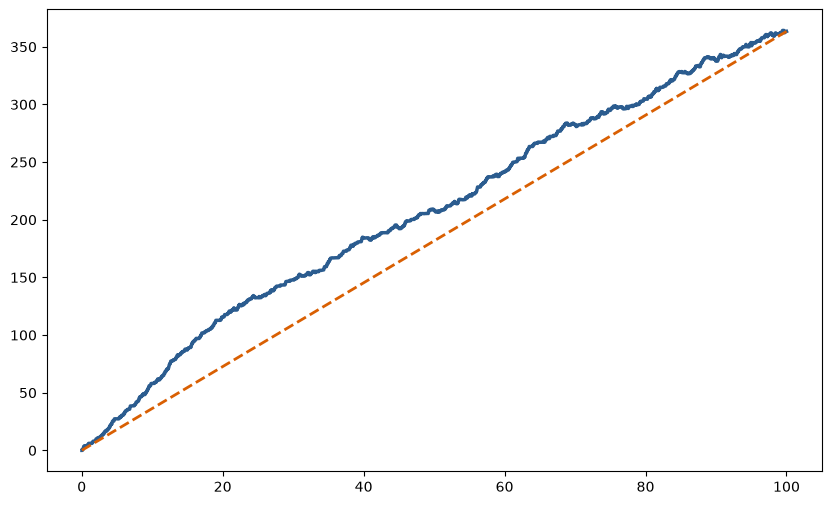

In [25]:
import matplotlib.pyplot as plt
# ---------------------------------------------------------
# Step 4: Plot the Qini Curve
# ---------------------------------------------------------

test_df = test_results.copy()
# X-axis: Percentage of Population Targeted
population_pct = (test_df.index + 1) / len(test_df) * 100

# Random Baseline Strategy Line (Diagonal from 0 to final Qini value)
total_qini_max = test_df['qini_score'].iloc[-1]
random_qini = population_pct / 100.0 * total_qini_max
plt.figure(figsize=(10, 6))

# Plot Uplift Model Curve
plt.plot(population_pct, test_df['qini_score'], label='T-Learner Uplift Model', color='#2b5c8f', lw=2.5)

# Plot Random Line
plt.plot(population_pct, random_qini, label='Random Targeting Baseline', color='#d95f02', linestyle='--', lw=2)

# Highlight Maximum Peak (Optimal Budget Cutoff)
max_qini_idx = test_df['qini_score'].idxmax()
optimal_pct = population_pct.iloc[max_qini_idx]
max_qini_val = test_df['qini_score'].iloc[max_qini_idx]

plt.scatter([optimal_pct], [max_qini_val], color='red', s=100, zorder=5)
plt.axvline(x=optimal_pct, color='red', linestyle=':', alpha=0.7, label=f'Optimal Cutoff ({optimal_pct:.1f}% Pop)')

# Formatting & Titles
plt.title('Qini Curve: Grid Power Churn Campaign Uplift', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Percentage of Total Customers Targeted (%)', fontsize=12)
plt.ylabel('Cumulative Incremental Retained Customers (Qini Metric)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='lower right')
plt.tight_layout()

plt.show()
